In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

RACINE = Path("..").resolve()
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

sns.set_theme(style="whitegrid")
PROCESSED = Path("../data/processed")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)

hc = pd.read_parquet(PROCESSED / "home_credit_clean.parquet")
cr = pd.read_parquet(PROCESSED / "credit_risk_clean.parquet")

In [2]:
print("HC taux de défaut :", hc["TARGET"].mean().round(4))
print("CR taux de défaut :", cr["loan_status"].mean().round(4))
print(hc.groupby("sans_emploi")["TARGET"].agg(taux="mean", n="size").round(4))

HC taux de défaut : 0.0835
CR taux de défaut : 0.2187
               taux       n
sans_emploi                
0            0.0900  226224
1            0.0548   52008


                          count      mean       std      min       25%  \
age_ans                278232.0      44.2      11.9     20.5      34.4   
anciennete_emploi_ans  226224.0       6.6       6.4     -0.0       2.1   
AMT_INCOME_TOTAL       278232.0  169069.5  245911.0  25650.0  112500.0   
AMT_CREDIT             278232.0  627965.7  405407.0  45000.0  297000.0   
AMT_ANNUITY            278220.0   28244.3   14167.2   1615.5   18103.5   
CNT_CHILDREN           278232.0       0.4       0.7      0.0       0.0   
CNT_FAM_MEMBERS        278232.0       2.1       0.9      1.0       2.0   

                            50%       75%          max  
age_ans                    43.5      54.2         69.0  
anciennete_emploi_ans       4.6       8.8         49.0  
AMT_INCOME_TOTAL       153000.0  202500.0  117000000.0  
AMT_CREDIT             540000.0  835380.0    4050000.0  
AMT_ANNUITY             26086.5   35694.0     258025.5  
CNT_CHILDREN                0.0       1.0         19.0  
CNT_FAM_

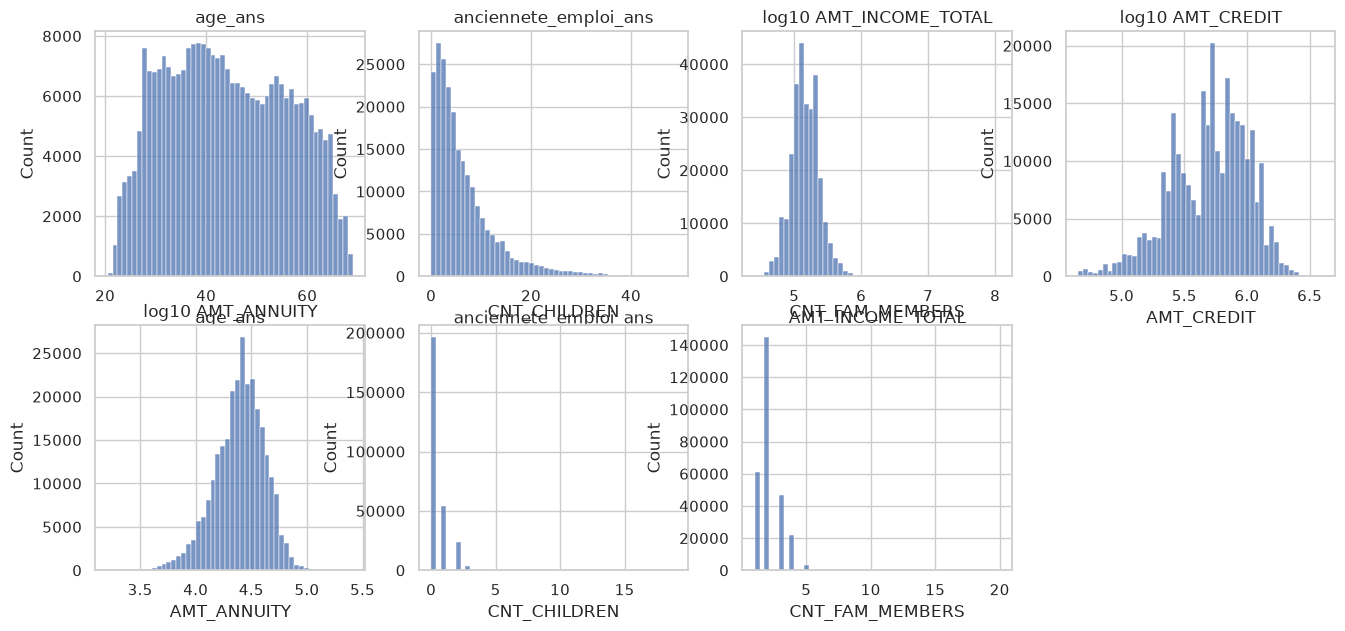

In [3]:
num = ["age_ans", "anciennete_emploi_ans", "AMT_INCOME_TOTAL", "AMT_CREDIT",
       "AMT_ANNUITY", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
print(hc[num].describe().round(1).T)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num):
    x = np.log10(hc[col]) if col.startswith("AMT") else hc[col]
    sns.histplot(x.dropna(), bins=50, ax=ax)
    ax.set_title(("log10 " if col.startswith("AMT") else "") + col)
axes.ravel()[-1].axis("off")
fig.savefig(FIG / "hc_distributions.png", dpi=150, bbox_inches="tight")

In [4]:
cats = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
        "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "FLAG_OWN_REALTY", "FLAG_OWN_CAR", "CODE_GENDER"]
for c in cats:
    t = hc.groupby(c, dropna=False)["TARGET"].agg(taux="mean", n="size")
    print(f"\n{c}\n", t.sort_values("taux", ascending=False).round(3))


NAME_INCOME_TYPE
                        taux       n
NAME_INCOME_TYPE                   
Maternity leave       1.000       2
Unemployed            0.533      15
Working               0.099  142719
Commercial associate  0.078   63652
State servant         0.060   19836
Pensioner             0.055   51993
Student               0.000      15

NAME_EDUCATION_TYPE
                                 taux       n
NAME_EDUCATION_TYPE                         
Lower secondary                0.110    3608
Secondary / secondary special  0.092  200125
Incomplete higher              0.089    9032
Higher education               0.057   65321
Academic degree                0.021     146

NAME_FAMILY_STATUS
                        taux       n
NAME_FAMILY_STATUS                 
Single / not married  0.103   39709
Civil marriage        0.102   26981
Separated             0.085   17846
Married               0.078  178711
Widow                 0.060   14985

NAME_HOUSING_TYPE
                       taux 

In [5]:
for col in ["age_ans", "anciennete_emploi_ans", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]:
    tranches = pd.qcut(hc[col], 10, duplicates="drop")
    print(f"\n{col}\n", hc.groupby(tranches, observed=True)["TARGET"].mean().round(3))


age_ans
 age_ans
(20.503, 28.482]    0.122
(28.482, 32.359]    0.113
(32.359, 36.312]    0.103
(36.312, 39.8]      0.092
(39.8, 43.461]      0.082
(43.461, 47.537]    0.079
(47.537, 52.071]    0.073
(52.071, 56.348]    0.065
(56.348, 60.958]    0.055
(60.958, 68.997]    0.050
Name: TARGET, dtype: float64

anciennete_emploi_ans
 anciennete_emploi_ans
(-0.001, 0.928]     0.115
(0.928, 1.719]      0.119
(1.719, 2.565]      0.116
(2.565, 3.491]      0.108
(3.491, 4.589]      0.099
(4.589, 6.021]      0.087
(6.021, 7.754]      0.077
(7.754, 10.168]     0.070
(10.168, 14.689]    0.061
(14.689, 49.04]     0.048
Name: TARGET, dtype: float64

AMT_INCOME_TOTAL
 AMT_INCOME_TOTAL
(25649.999, 81000.0]       0.083
(81000.0, 99000.0]         0.085
(99000.0, 112500.0]        0.089
(112500.0, 135000.0]       0.088
(135000.0, 153000.0]       0.092
(153000.0, 166500.0]       0.089
(166500.0, 189000.0]       0.086
(189000.0, 225000.0]       0.081
(225000.0, 270000.0]       0.073
(270000.0, 117000000.0]  

In [6]:
hc["credit_sur_revenu"] = hc["AMT_CREDIT"] / hc["AMT_INCOME_TOTAL"]
hc["annuite_sur_revenu"] = hc["AMT_ANNUITY"] / hc["AMT_INCOME_TOTAL"]
hc["duree_implicite"] = hc["AMT_CREDIT"] / hc["AMT_ANNUITY"]
print(hc[["credit_sur_revenu", "annuite_sur_revenu", "duree_implicite"]].describe().round(2).T)

                       count   mean   std   min    25%    50%    75%    max
credit_sur_revenu   278232.0   4.15  2.74  0.00   2.18   3.50   5.45  84.74
annuite_sur_revenu  278220.0   0.19  0.09  0.00   0.12   0.17   0.24   1.88
duree_implicite     278220.0  21.78  8.21  8.04  14.96  20.68  27.84  45.31


In [7]:
for c in ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]:
    print(cr.groupby(c)["loan_status"].agg(taux="mean", n="size").sort_values("taux", ascending=False).round(3), "\n")

for col in ["person_age", "person_income", "loan_amnt", "loan_percent_income", "cb_person_cred_hist_length"]:
    tranches = pd.qcut(cr[col], 8, duplicates="drop")
    print(col, "\n", cr.groupby(tranches, observed=True)["loan_status"].mean().round(3), "\n")

                        taux      n
person_home_ownership              
RENT                   0.316  16374
OTHER                  0.311    106
MORTGAGE               0.126  13366
OWN                    0.075   2563 

                    taux     n
loan_intent                   
DEBTCONSOLIDATION  0.287  5189
MEDICAL            0.268  6042
HOMEIMPROVEMENT    0.262  3594
PERSONAL           0.199  5496
EDUCATION          0.173  6409
VENTURE            0.149  5679 

                            taux      n
cb_person_default_on_file              
Y                          0.379   5729
N                          0.184  26680 

person_age 
 person_age
(19.999, 22.0]    0.259
(22.0, 23.0]      0.215
(23.0, 24.0]      0.218
(24.0, 26.0]      0.217
(26.0, 28.0]      0.215
(28.0, 30.0]      0.201
(30.0, 35.0]      0.202
(35.0, 94.0]      0.210
Name: loan_status, dtype: float64 

person_income 
 person_income
(3999.999, 30000.0]      0.456
(30000.0, 38500.0]       0.325
(38500.0, 47000.0]       0

In [8]:
# 1. Valeurs manquantes
print(hc.isna().mean().round(3).sort_values(ascending=False).head(8))

# 2. Queue du revenu et des ratios
print(hc["AMT_INCOME_TOTAL"].quantile([.5, .99, .995, .999]))
print((hc["AMT_INCOME_TOTAL"] > 1_000_000).sum(), "revenus > 1 000 000")

# 3. Défaut par décile des ratios (affichage compact)
for col in ["credit_sur_revenu", "annuite_sur_revenu", "duree_implicite"]:
    t = hc.groupby(pd.qcut(hc[col], 10, duplicates="drop"), observed=True)["TARGET"].mean().round(3)
    print(col); print(t.to_string(), "\n")

# 4. Annuité > revenu
print((hc["annuite_sur_revenu"] > 1).sum(), "lignes avec annuité > revenu")

OCCUPATION_TYPE          0.319
anciennete_emploi_ans    0.187
CODE_GENDER              0.000
TARGET                   0.000
SK_ID_CURR               0.000
CNT_FAM_MEMBERS          0.000
CNT_CHILDREN             0.000
AMT_INCOME_TOTAL         0.000
dtype: float64
0.500    153000.0000
0.990    450000.0000
0.995    574438.2525
0.999    900000.0000
Name: AMT_INCOME_TOTAL, dtype: float64
179 revenus > 1 000 000
credit_sur_revenu
credit_sur_revenu
(0.00381, 1.396]    0.073
(1.396, 1.938]      0.082
(1.938, 2.428]      0.091
(2.428, 2.941]      0.095
(2.941, 3.5]        0.094
(3.5, 4.161]        0.093
(4.161, 5.0]        0.084
(5.0, 6.0]          0.077
(6.0, 7.692]        0.074
(7.692, 84.737]     0.071 

annuite_sur_revenu
annuite_sur_revenu
(-0.000776, 0.0868]    0.077
(0.0868, 0.112]        0.076
(0.112, 0.132]         0.080
(0.132, 0.152]         0.084
(0.152, 0.172]         0.086
(0.172, 0.194]         0.085
(0.194, 0.221]         0.086
(0.221, 0.255]         0.090
(0.255, 0.309]        

# Analyse exploratoire des données

## 1. Objectif et périmètre

Cette analyse porte sur les jeux de données nettoyés : **Home Credit Default Risk** (jeu principal) et **Credit Risk Dataset** (jeu complémentaire). Elle vise à :
1. décrire les distributions des variables retenues ;
2. mesurer le lien entre chaque variable et le défaut de paiement ;
3. repérer les valeurs aberrantes, les modalités rares et les biais éventuels, avant la phase de modélisation.

Le nettoyage n'impute aucune valeur manquante. L'imputation est réalisée plus tard, dans le pipeline de modélisation, et ajustée sur l'échantillon d'apprentissage uniquement, afin d'éviter toute fuite d'information vers l'échantillon de test.

## 2. Jeux de données après nettoyage

| Jeu | Lignes | Colonnes | Opérations principales |
|---|---|---|---|
| Home Credit (`application_train`) | 278 232 | 18 | Conservation des seuls « Cash loans » (29 279 lignes retirées) ; conversion des jours en années ; traitement de la valeur sentinelle `DAYS_EMPLOYED = 365243` |
| Credit Risk Dataset | 32 409 | 10 | 165 doublons retirés ; 5 âges > 100 ans et 2 ancienneté impossibles retirés ; suppression de `loan_grade` et `loan_int_rate` |

**Valeur sentinelle.** 52 008 lignes portent `DAYS_EMPLOYED = 365243`, valeur impossible (environ 1 000 ans), qui correspond à des clients sans emploi déclaré (retraités notamment). Elle est remplacée par une valeur manquante, et l'information est conservée dans l'indicateur binaire `sans_emploi`.

**Variables écartées.**
- `loan_grade` et `loan_int_rate` : elles sont calculées par le prêteur *après* évaluation du risque. Elles contiennent donc la réponse (fuite de cible).
- `EXT_SOURCE_*` : scores externes indisponibles dans le contexte sénégalais.
- Le sexe est conservé uniquement pour l'audit d'équité et n'est jamais une variable explicative du modèle.

## 3. Constats sur Home Credit

**Déséquilibre des classes.** Le taux de défaut sur le jeu brut est de 8,07 % (91,93 % de remboursements). Le déséquilibre impose des métriques adaptées (AUC, précision/rappel, KS) et non la simple exactitude.

**Âge.** La relation avec le défaut est monotone : de 12,2 % (20-28 ans) à 5,0 % (61-69 ans). Plus le client est âgé, moins il fait défaut.

**Ancienneté dans l'emploi.** Le taux de défaut diminue avec l'ancienneté : 11,5 % pour moins d'un an, 7,0 % pour 8 à 10 ans.

**Type de revenu.**

| Type | Taux de défaut |
|---|---|
| Working | 9,9 % |
| Commercial associate | 7,8 % |
| State servant | 6,0 % |
| Pensioner | 5,5 % |

Les modalités *Maternity leave* (2 cas), *Unemployed* (15 cas) et *Student* (15 cas) ont des effectifs trop faibles pour être interprétées. Elles seront regroupées dans une modalité « Autre ».

**Niveau d'éducation.** Le taux de défaut passe de 11,0 % (secondaire inférieur) à 5,7 % (enseignement supérieur). Cette variable agit comme un indicateur du statut socio-économique. Son usage est discuté dans l'audit d'équité.

**Sexe.** Le taux de défaut est de 10,6 % pour les hommes et de 7,2 % pour les femmes. L'écart est documenté mais le sexe n'est pas utilisé comme variable du modèle, pour des raisons éthiques et d'équité.

**Valeurs extrêmes.**
- `AMT_INCOME_TOTAL` : médiane 153 000, 99,5ᵉ percentile 574 438, maximum 117 000 000 (179 lignes au-dessus de 1 000 000). Plafonnement au 99,5ᵉ percentile.
- Valeurs manquantes : `OCCUPATION_TYPE` 31,9 % (traitée comme modalité « Non renseigné ») ; `anciennete_emploi_ans` 18,7 %, correspondant exactement aux clients `sans_emploi` (absence structurelle, remplie par 0 avec l'indicateur `sans_emploi`).

Traitement retenu : plafonnement (winsorisation) au 99,5ᵉ percentile pour les montants, et plafonnement des effectifs familiaux. Aucune ligne n'est supprimée.

## 4. Variables dérivées (ratios)

| Variable | Définition | Médiane | Min – Max |
|---|---|---|---|
| `credit_sur_revenu` | AMT_CREDIT / AMT_INCOME_TOTAL | 3,50 | 0,00 – 84,74 |
| `annuite_sur_revenu` | AMT_ANNUITY / AMT_INCOME_TOTAL | 0,17 | 0,00 – 1,88 |
| `duree_implicite` | AMT_CREDIT / AMT_ANNUITY (nombre de versements) | 20,68 | 8,04 – 45,31 |

Ces ratios sont **sans unité** : ils restent valables quelle que soit la monnaie, ce qui facilite la transposition vers le contexte sénégalais (FCFA). `duree_implicite` suppose des versements mensuels (hypothèse non précisée dans la description du jeu). Elle sous-estime légèrement la durée réelle puisque les intérêts ne sont pas isolés.

Défaut par décile de chaque ratio : Le taux de défaut par décile de `credit_sur_revenu` n'est **pas monotone** : il augmente de 7,3 % (ratio < 1,4) jusqu'à environ 9,5 % (ratio entre 2,4 et 3,5), puis diminue pour les ratios élevés (7,7 % entre 5 et 6, 5,8 % pour le dernier décile). Ce comportement contre-intuitif s'explique vraisemblablement par un **biais de sélection** : les crédits élevés par rapport au revenu n'ont été accordés qu'à des clients au profil par ailleurs très favorable, et les dossiers refusés sont absents des données.

Pour que la suggestion de montant reste cohérente (un montant plus faible ne doit jamais augmenter le risque), une **contrainte de monotonie** sera imposée au modèle sur les variables de montant et d'annuité rapportées au revenu.Les taux de défaut par sextile confirment des relations faibles et en partie non monotones :

| Variable | Tranche basse | Tranche intermédiaire | Tranche haute |
|---|---|---|---|
| `credit_sur_revenu` | 7,6 % | 9,5 % | 7,2 % |
| `annuite_sur_revenu` | 7,6 % | 8,8 % | 8,5 % |
| `duree_implicite` | 8,0 % | 9,4 % (puis 7,4 %) | 5,9 % |

Seul `annuite_sur_revenu` (taux d'endettement) présente une relation quasi croissante avec le défaut. Les relations inversées pour les crédits élevés et les durées longues traduisent le biais de sélection : ces crédits n'ont été accordés qu'à des clients très solides par ailleurs.

**Choix de conception.** La suggestion de montant conserve la durée constante et ne fait varier que le montant. Une contrainte de monotonie croissante est imposée au modèle sur `credit_sur_revenu` et `annuite_sur_revenu`, garantissant qu'une réduction du montant ne peut qu'abaisser le risque estimé. La durée n'est pas contrainte.


## 5. Constats sur le Credit Risk Dataset

Le taux de défaut brut est de 21,8 %.

| Variable | Modalité | Taux de défaut |
|---|---|---|
| Statut de logement | Locataire (RENT) | 31,6 % |
| | Hypothèque (MORTGAGE) | 12,6 % |
| | Propriétaire (OWN) | 7,5 % |
| Objet du prêt | Consolidation de dettes | 28,7 % |
| | Frais médicaux | 26,8 % |
| | Études | 17,3 % |
| | Projet d'entreprise (VENTURE) | 14,9 % |
| Défaut antérieur enregistré | Oui | 37,9 % |
| | Non | 18,4 % |

L'historique de défaut (`cb_person_default_on_file`) est la variable la plus discriminante. Elle correspond, dans notre application, à l'historique interne de l'institution de microfinance.

## 6. Limites identifiées

1. **Décalage de contexte.** Les données proviennent de clientèles étrangères (Home Credit, jeu de prêts personnels). Les catégories professionnelles ne reflètent pas le secteur informel sénégalais. Les performances obtenues ne sont donc pas transposables telles quelles.
2. **Biais de sélection.** Seuls les clients dont le crédit a été accordé figurent dans les données. Le comportement des demandes refusées est inconnu.
3. **Jeu complémentaire simplifié.** Le Credit Risk Dataset est structurellement plus simple et donne des performances élevées même sans les variables à fuite. Il est utilisé comme complément et non comme référence principale.
4. **Équité.** Le sexe et le niveau d'éducation présentent des écarts de défaut marqués. Un audit d'équité sera réalisé sur le modèle final.

## 7. Décisions pour la suite

- Regrouper les modalités rares de `NAME_INCOME_TYPE`.
- Plafonner les montants au 99,5ᵉ percentile et les effectifs familiaux.
- Utiliser des ratios sans unité plutôt que les montants bruts.
- Imputer dans le pipeline de modélisation, ajusté sur l'apprentissage uniquement.
- Exclure du modèle le sexe, `loan_grade`, `loan_int_rate` et `EXT_SOURCE_*`.

In [15]:
for col in ["credit_sur_revenu", "annuite_sur_revenu", "duree_implicite"]:
    t = hc.groupby(pd.qcut(hc[col], 6, duplicates="drop"), observed=True)["TARGET"].agg(["mean", "size"]).round(3)
    print(col); print(t.to_string(), "\n")

credit_sur_revenu
                    mean   size
credit_sur_revenu              
(0.00381, 1.756]   0.076  46387
(1.756, 2.586]     0.090  46357
(2.586, 3.5]       0.095  46471
(3.5, 4.684]       0.090  46273
(4.684, 6.465]     0.079  46372
(6.465, 84.737]    0.072  46372 

annuite_sur_revenu
                     mean   size
annuite_sur_revenu              
(-0.000776, 0.104]  0.076  46370
(0.104, 0.139]      0.082  46370
(0.139, 0.172]      0.084  46370
(0.172, 0.211]      0.086  46427
(0.211, 0.27]       0.088  46327
(0.27, 1.876]       0.085  46356 

duree_implicite
                              mean   size
duree_implicite                          
(8.036000000000001, 12.658]  0.080  46382
(12.658, 17.816]             0.094  46358
(17.816, 20.677]             0.117  46718
(20.677, 25.162]             0.074  46023
(25.162, 31.001]             0.076  46370
(31.001, 45.305]             0.059  46369 



In [13]:
import sys
from pathlib import Path

RACINE = Path("..").resolve()      # notebooks/ -> racine du projet
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))
from src.features import construire_variables
hc_f = construire_variables(hc.drop(columns=["credit_sur_revenu", "annuite_sur_revenu", "duree_implicite"]))
print(hc_f.shape)
print(hc_f[["AMT_INCOME_TOTAL", "credit_sur_revenu", "annuite_sur_revenu"]].describe().round(2))
print(hc_f["NAME_INCOME_TYPE"].value_counts())

(278232, 21)
       AMT_INCOME_TOTAL  credit_sur_revenu  annuite_sur_revenu
count         278232.00          278232.00           278220.00
mean          167331.02               4.15                0.19
std            85392.35               2.74                0.09
min            25650.00               0.08                0.01
25%           112500.00               2.19                0.12
50%           153000.00               3.50                0.17
75%           202500.00               5.45                0.24
max           574438.00              84.74                1.00
NAME_INCOME_TYPE
Working                 142719
Commercial associate     63652
Pensioner                51993
State servant            19836
Autre                       32
Name: count, dtype: int64


In [18]:
print(hc_f["credit_sur_revenu"].quantile([.99, .995, .999]))

0.990    13.318475
0.995    15.000000
0.999    19.690352
Name: credit_sur_revenu, dtype: float64


In [6]:
import src.features as f
print(f.PLAFOND_RATIO_CREDIT)

15


In [8]:
from src.features import construire_variables

hc_f = construire_variables(hc)
print(hc_f["credit_sur_revenu"].describe().round(2))

hc_f.to_parquet("../data/processed/home_credit_features.parquet", index=False)
print(hc_f.shape)

count    278232.00
mean          4.13
std           2.65
min           0.08
25%           2.19
50%           3.50
75%           5.45
max          15.00
Name: credit_sur_revenu, dtype: float64
(278232, 21)
